# Who is who in EHR generation?

### Description

The dataset contains a mixture of demographic, clinical, laboratory, diagnosis, utilization, and discharge-related variables. Examples include age, BMI, blood pressure, heart rate, glucose, creatinine, diagnosis category, smoking status, number of medications, previous visits, and length of stay.

All records are fully synthetic and do not correspond to real patients.

The target variable contains four anonymized classes:
- Model_A
- Model_B
- Model_C
- Model_D

These correspond to four different LLMs used to generate the data.

For this challenge, the predictive model must be Logistic Regression. Participants are encouraged to improve performance through representation and preprocessing rather than by changing the classifier. Useful directions may include categorical encoding, missing-value strategies, scaling, binning, transformations, interaction features, and clinically motivated feature engineering.

### Files

- train.csv - the training set
- test.csv - the test set
- sample_submission.csv - a sample submission file in the correct format

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv('./train.csv')
test = pd.read_csv('./test.csv')

## Com es aquest dataset?

In [3]:
print(train.shape)
train.head()

(2400, 26)


,id,age,sex,bmi,smoking_status,encounter_type,systolic_bp,diastolic_bp,heart_rate,respiratory_rate,...,diabetes,hypertension,chronic_kidney_disease,primary_diagnosis,num_medications,prior_visits_12m,length_of_stay_days,discharge_destination,readmitted_30d,label
0,5be091fe7010722968d37fbbbfa5adec,38,Male,30.4,Current,Urgent,160,95,105,28,...,No,No,No,Respiratory,6,10,3.0,Home,No,Model_B
1,7ebc8ab8f1dfede1237163cb2e71325f,48,Female,28.5,Current,Elective,128,76,78,16,...,No,No,No,Gastrointestinal,3,2,2.0,Home,No,Model_D
2,69f51e35fec3bda1d81f2cbf9ac8b827,53,Female,25.4,Never,Elective,130,78,77,19,...,No,No,No,Renal,1,1,3.0,Rehabilitation,No,Model_A
3,8c64aa346b72cad6cb179f254abfd71d,45,Male,28.2,Never,Elective,145,95,72,18,...,Yes,No,No,Cardiovascular,4,0,4.0,Home,No,Model_C
4,c8255d88bcfc566c5616bed411b55bd7,41,Male,27.9,Current,Emergency,150,94,115,22,...,No,No,No,Gastrointestinal,2,5,3.0,HomeHealth,No,Model_B


In [4]:
train.info(verbose=True, max_cols= 30, show_counts= True)

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      2400 non-null   str    
 1   age                     2400 non-null   int64  
 2   sex                     2400 non-null   str    
 3   bmi                     2132 non-null   float64
 4   smoking_status          2400 non-null   str    
 5   encounter_type          2400 non-null   str    
 6   systolic_bp             2400 non-null   int64  
 7   diastolic_bp            2400 non-null   int64  
 8   heart_rate              2400 non-null   int64  
 9   respiratory_rate        2400 non-null   int64  
 10  temperature_c           2400 non-null   float64
 11  spo2                    2400 non-null   int64  
 12  glucose_mg_dl           1864 non-null   float64
 13  creatinine_mg_dl        1828 non-null   float64
 14  sodium_mmol_l           1900 non-null   float64
 15

Tenim 25 variables, 24 que aniran a X i 1 que anira a Y. Veiem que la variable que volem aïllar es la variable 'label'. També podem veure que hi han variables amb nombre null (bmi,glucose_mg_dl, creatinine_mg_dl, sodium_mmol_l, hemoglobin_g_dl  )

Anem a dividir les variables per una millor comprensió:

**categoriques**
- sense ordre:
    - id  ->  ( crec q es pot eliminar )
    - primary_diagnosis
    - discharge_destination
    - label ( variable objectiu)
- amb ordre:
    - smoking status
    - encounter_type
- si/no o A/B:
    - sex
    - diabetes
    - hypertension
    - chronic_kidney_disease
    - discharge_destination

**numeriques**
- quantitativa:
    - age (int64): Edat.
    - systolic_bp (int64): Pressió arterial sistòlica.
    - diastolic_bp (int64): Pressió arterial diastòlica.
    - heart_rate (int64): Freqüència cardíaca.
    - respiratory_rate (int64): Freqüència respiratòria.
    - spo2 (int64): Saturació d'oxigen.
    - num_medications (int64): Nombre de medicaments.
    - prior_visits_12m (int64): Visites prèvies en els últims 12 mesos.
- contínua:
    - bmi (float64): Índex de massa corporal.
    - temperature_c (float64): Temperatura en graus Celsius.
    - glucose_mg_dl (float64): Nivell de glucosa.
    - creatinine_mg_dl (float64): Nivell de creatinina.
    - sodium_mmol_l (float64): Nivell de sodi.
    - hemoglobin_g_dl (float64): Nivell d'hemoglobina.
    - length_of_stay_days (float64): Dies d'estada hospitalària.


In [52]:
# Variables numèriques (continuen i discretes)
num_features = [
     'age', 'bmi', 'systolic_bp', 'diastolic_bp', 'heart_rate', 
    'respiratory_rate', 'temperature_c', 'glucose_mg_dl', 'spo2',
    'creatinine_mg_dl', 'hemoglobin_g_dl', 'sodium_mmol_l',
    'num_medications', 'prior_visits_12m', 'length_of_stay_days', 
]


# Variables categòriques (incloses les binàries de tipus text)
cat_features = [
    'sex', 'smoking_status', 'encounter_type', 'diabetes', 
    'hypertension', 'chronic_kidney_disease', 'primary_diagnosis', 
    'discharge_destination', 'readmitted_30d', 
]

# Descartem 'id'

In [53]:
# Variables numéricas discretas
discrete_features = [
    "age",
    "systolic_bp",
    "diastolic_bp",
    "heart_rate",
    "respiratory_rate",
    "spo2",
    "num_medications",
    "prior_visits_12m",
]

# Variables numéricas continuas
continuous_features = [
    "bmi",
    "temperature_c",
    "glucose_mg_dl",
    "creatinine_mg_dl",
    "hemoglobin_g_dl",
    "sodium_mmol_l",
    "length_of_stay_days",
]

# Variables categóricas
cat_features = [
    "sex",
    "smoking_status",
    "encounter_type",
    "diabetes",
    "hypertension",
    "chronic_kidney_disease",
    "primary_diagnosis",
    "discharge_destination",
    "readmitted_30d",
]

In [54]:
for el in cat_features:
    print('------------')
    print(train[el].value_counts())
    print(f"Unique values: {train[el].nunique()}")

------------
sex
Male      1222
Female    1178
Name: count, dtype: int64
Unique values: 2
------------
smoking_status
Never      1025
Former      711
Current     636
Unknown      28
Name: count, dtype: int64
Unique values: 4
------------
encounter_type
Outpatient    940
Elective      571
Emergency     559
Urgent        330
Name: count, dtype: int64
Unique values: 4
------------
diabetes
No     2016
Yes     384
Name: count, dtype: int64
Unique values: 2
------------
hypertension
No     1624
Yes     776
Name: count, dtype: int64
Unique values: 2
------------
chronic_kidney_disease
No     2088
Yes     312
Name: count, dtype: int64
Unique values: 2
------------
primary_diagnosis
Cardiovascular      502
Gastrointestinal    430
Respiratory         347
Musculoskeletal     240
Infectious          218
Neurological        203
Renal               167
Other               153
Endocrine           140
Name: count, dtype: int64
Unique values: 9
------------
discharge_destination
Home              1835

Ideas per a variables categoriques: 
- En les variables binarias o de A/B utilitzar OneHotEncode. I que fer amb la resta de variables categoriques.
- En les variables: bmi,glucose_mg_dl, creatinine_mg_dl, sodium_mmol_l, hemoglobin_g_dl. Pensar q volem fer amb elles per treure els nulls.
    -  en smoking_status hi ha una variable = unknown, no se com tractar aixó, si com a info o sense info
- ALgunes variables categoricas estan prou descompensades com la diabetes, revisar

Number of unique values in age :65


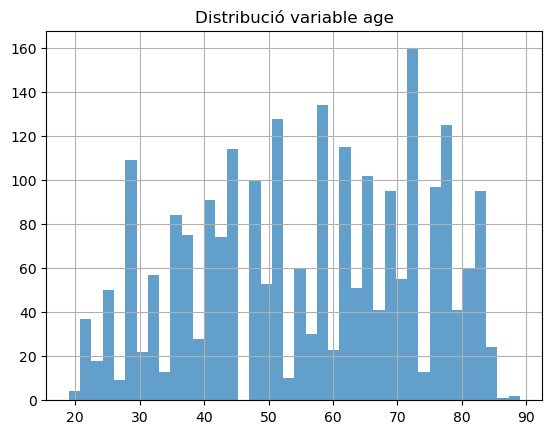

In [55]:
train['age'].hist(bins=40, alpha=0.7)
print ( f'Number of unique values in age :{train['age'].nunique()}')
plt.title('Distribució variable age')
plt.show()

Idea: Potser ho podem juntar per grups d'edat ? 

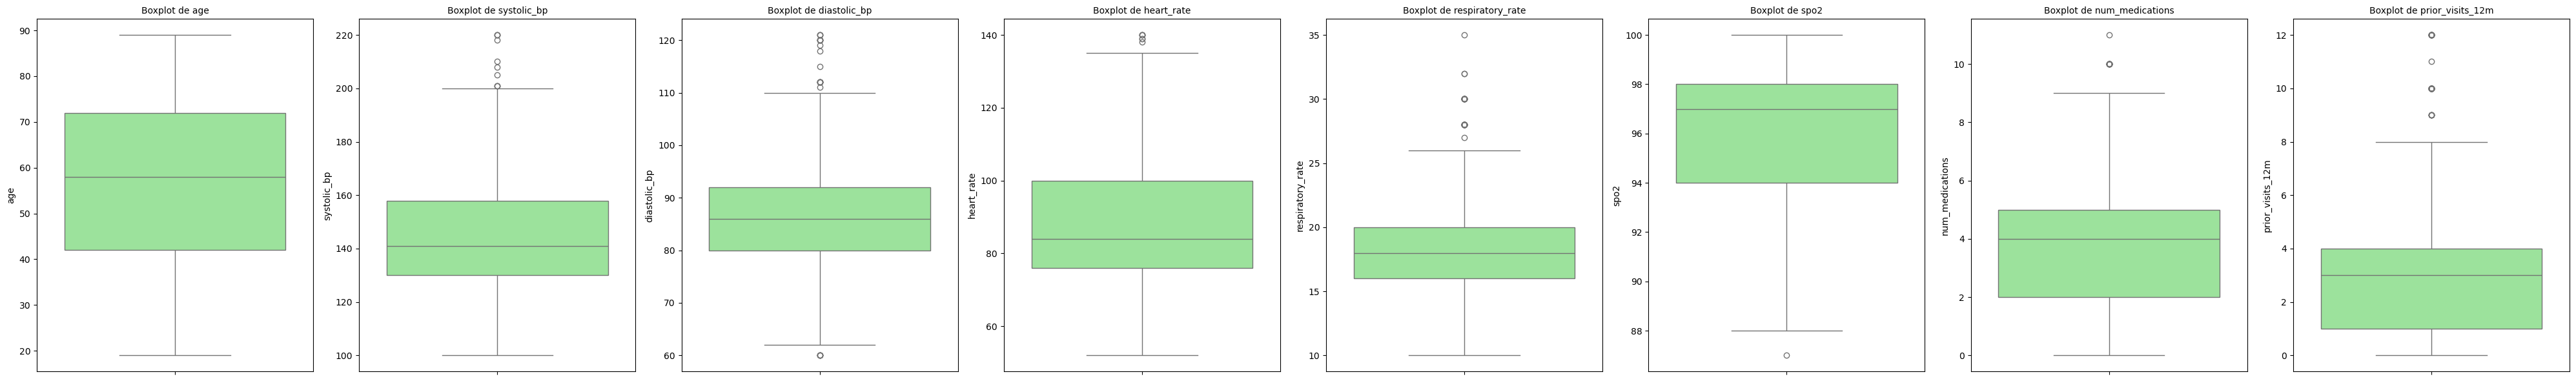

In [56]:
import seaborn as sns

# Crear figura amb dimensions adequades
plt.figure(figsize=(40, 6))  # Amplada major per col·locar múltiples gràfics en fila

# Generar boxplots
for i, col in enumerate(discrete_features):
    plt.subplot(1, len(discrete_features), i + 1)  # 1 fila, tantes columnes com variables
    sns.boxplot(y=train[col], color="lightgreen")  # Orientació vertical
    plt.title(f'Boxplot de {col}', fontsize=10)

# Mostrar gràfics
plt.tight_layout()
plt.show()

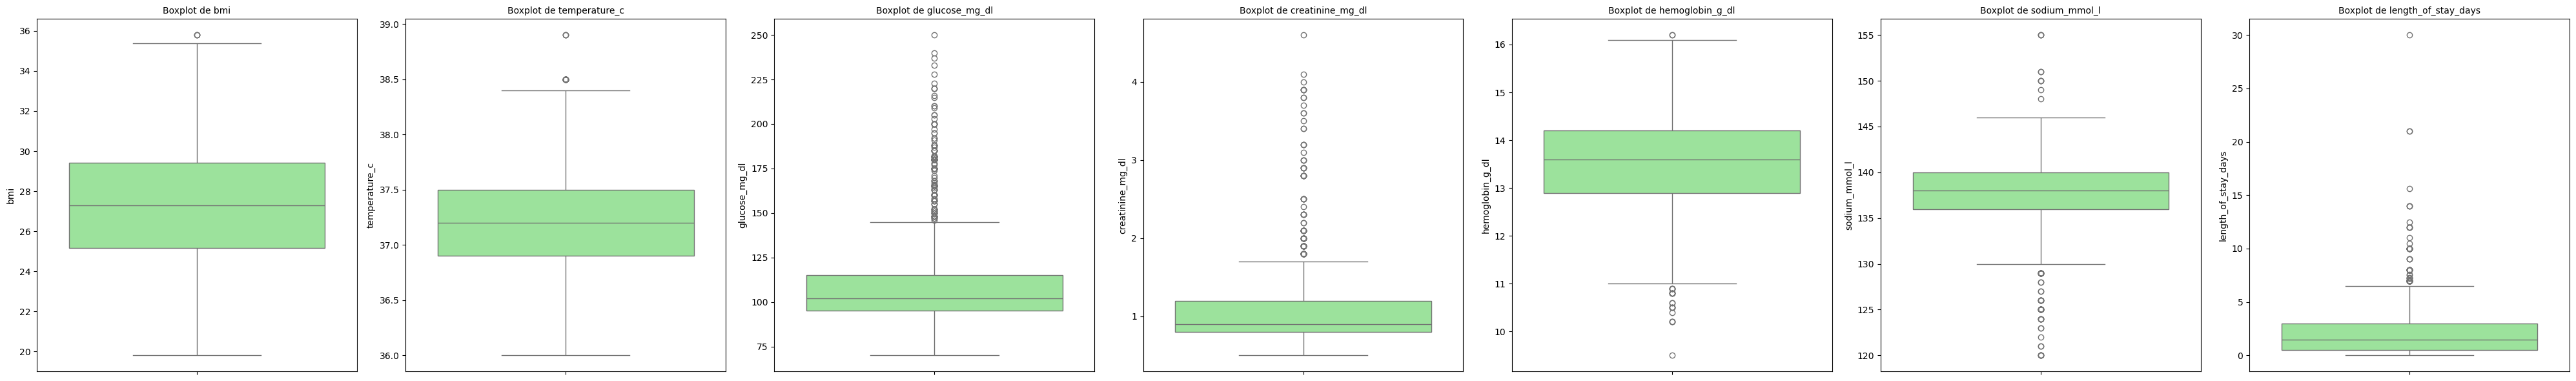

In [57]:
import seaborn as sns

# Crear figura amb dimensions adequades
plt.figure(figsize=(40, 6))  # Amplada major per col·locar múltiples gràfics en fila

# Generar boxplots
for i, col in enumerate(continuous_features):
    plt.subplot(1, len(continuous_features), i + 1)  # 1 fila, tantes columnes com variables
    sns.boxplot(y=train[col], color="lightgreen")  # Orientació vertical
    plt.title(f'Boxplot de {col}', fontsize=10)

# Mostrar gràfics
plt.tight_layout()
plt.show()

( dura molt el codi de dalt, no us espanteu )
Veiem que hi han variables numeriques amb prous outliers :/ ->  hem de pensar q fem

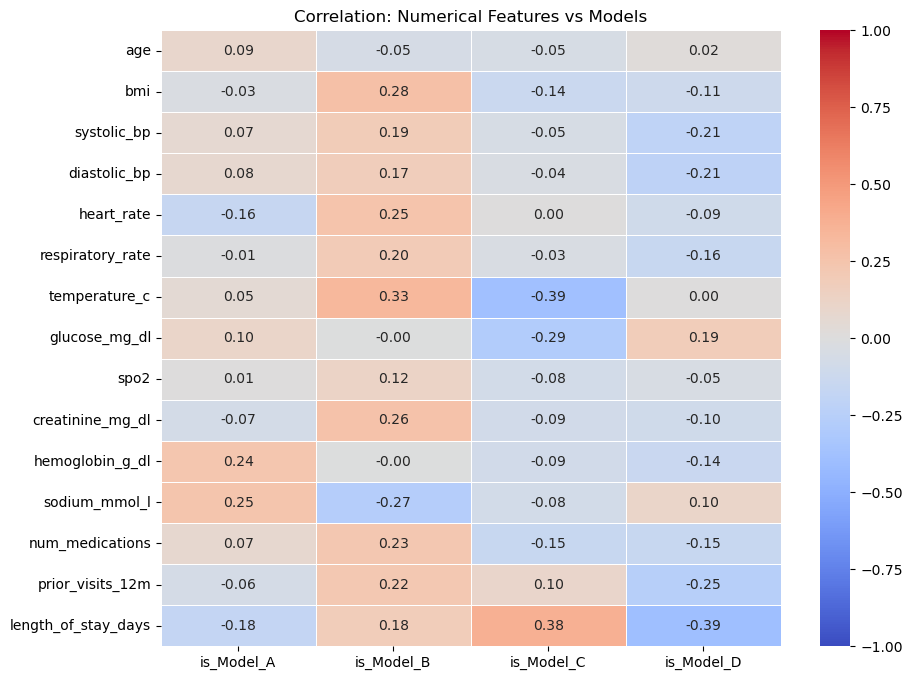

In [58]:
y_encoded = pd.get_dummies(train["label"], prefix="is")

correlation_matrix = pd.concat(
    [train[num_features], y_encoded],
    axis=1
).corr()

# Mostrar solo correlaciones entre features numéricas y output
correlation_matrix = correlation_matrix.loc[
    num_features, y_encoded.columns
]

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    linewidths=0.4,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation: Numerical Features vs Models")
plt.show()


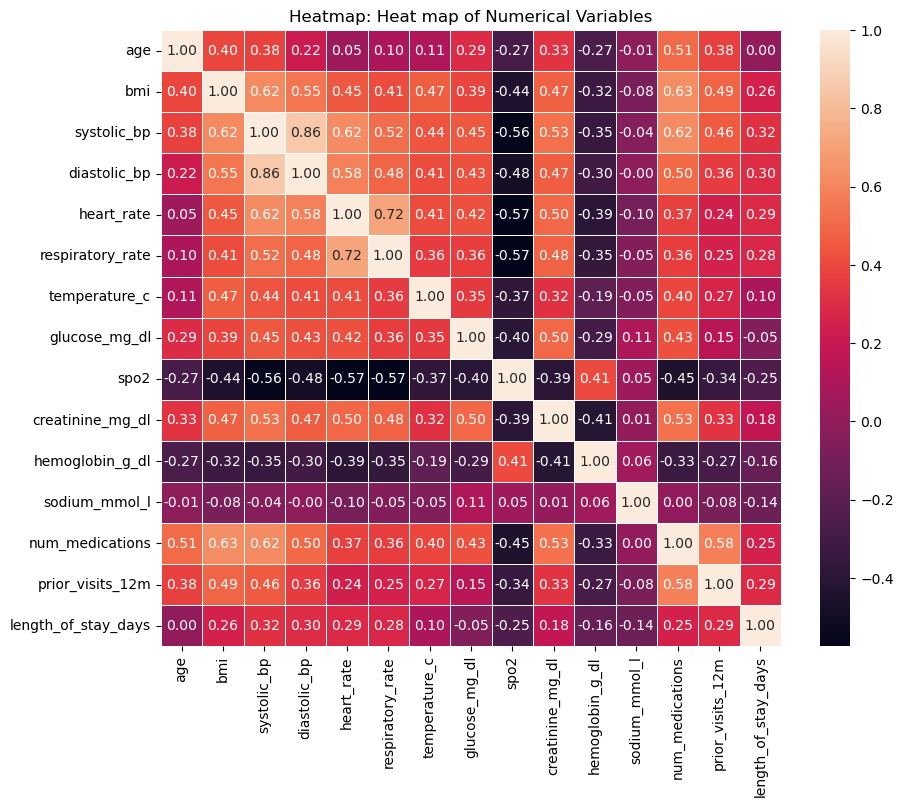

In [59]:

plt.figure(figsize=(10, 8))
correlation_matrix = train[num_features].corr()
sns.heatmap(
    correlation_matrix, 
    annot=True, 
    #cmap="Greens", 
    fmt=".2f", 
    linewidths=0.4
)
plt.title("Heatmap: Heat map of Numerical Variables")
plt.show()

## EVALUACIÓN CON LINEAR REGRESSOR

De momento solo provamos con train.csv asi el "test" que nos salga sera como "evaluation"

In [60]:
train = pd.read_csv('./train.csv')
test = pd.read_csv('./test.csv')

In [ ]:
# Variables numéricas discretas
discrete_features = [
    "age",
    "systolic_bp",
    "diastolic_bp",
    "heart_rate",
    "respiratory_rate",
    "spo2",
    "num_medications",
    "prior_visits_12m",
]

# Variables numéricas continuas
continuous_features = [
    "bmi",
    "temperature_c",
    "glucose_mg_dl",
    "creatinine_mg_dl",
    "hemoglobin_g_dl",
    "sodium_mmol_l",
    "length_of_stay_days",
]

# Variables categóricas
cat_features = [
    "sex",
    "smoking_status",
    "encounter_type",
    "diabetes",
    "hypertension",
    "chronic_kidney_disease",
    "primary_diagnosis",
    "discharge_destination",
    "readmitted_30d",
]

In [61]:
X = train.drop(columns=["id","label"])
y = train["label"]

preprocessing de les variables. Abans de fer la 1a prova no volia posar res pero clar, si no les variables categoriques no ens serviran.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer

# Pipeline para discretas
discrete_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Pipeline para continuas
continuous_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
])

# Pipeline para categóricas
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

In [70]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("discrete", discrete_pipeline, discrete_features),
    ("continuous", continuous_pipeline, continuous_features),
    ("categorical", cat_pipeline, cat_features),
])

In [71]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

el modelo:

In [72]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        C=1.0,
        random_state=42
    ))
])

In [73]:
from sklearn.metrics import accuracy_score, classification_report

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Tain accuracy:", accuracy_score(y_train, model.predict(X_train)))
print("Validation accuracy:", accuracy_score(y_test, y_pred))


Tain accuracy: 0.8182291666666667
Validation accuracy: 0.7583333333333333


model bàsic:
- train-> 0.8166
- eval -> 0.7583
- test -> 0.71750

sense 'sodium_mmol_l':  -> no millora, no provem per entregar
- train-> 0.8078125
- eval -> 0.7416

sense 'spo2':
- train -> 0.788
- eval -> 0.731

sense 'age':        -> podem provar de modificar la variable age per grups d'edat ja que veiem que actualment no ajuda res al model
- train-> 0.8197
- eval -> 0.7604

afegint 'age_group' i deixant 'age':
- train-> 0.8197
- eval -> 0.7562

afegint 'age_group' i eliminant 'age':
- train ->0.8208
- eval -> 0.7562

SEPARANT NUMERIQUES:
- train ->0.8156
- eval -> 0.7604

# EVALUACIÓ PER ENTREGAR

Aqui si que utilitzarem el test.csv. ( Millor basar nos nomes en el de dalt ) --> Faig un primer per a que vegin que estem en la competició

In [74]:
#Separar train & test real

print("Començem nombran train, test")
X_train = train.drop(columns=["label","id"])
y_train = train["label"]

test_ids = test["id"]
X_test = test.drop(columns=["id"])

#Ja tenim totes les configuracions d'abans aixi que nomes ens cal tornar a evaluar el model trobat

model.fit(X_train, y_train)

predictions = model.predict(X_test)

# Create the submission DataFrame
submission = pd.DataFrame({
    "id": test_ids,
    "label": predictions
})

# Save to CSV
submission.to_csv("submission.csv", index=False)

print(submission.head())
print("Submission shape:", submission.shape)


Començem nombran train, test
                                 id    label
0  0102f98c5fd7ed84754c58fe0d7f013f  Model_D
1  e2fa3e497f5bdb8c79748c7c0611fad0  Model_B
2  818a6ec782d097abc1ce67c42299d06a  Model_A
3  54e46a096cb47b5499a986477be83061  Model_B
4  5da9e7a746719fc3950c6e579c82bfa1  Model_C
Submission shape: (1600, 2)
